In [12]:
import re, random, math, os
from collections import Counter
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence
from datasets import load_dataset
from tqdm import tqdm

In [13]:
# --------------------------
# 0) Configuración general
# --------------------------
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Hiperparámetros principales
BATCH_SIZE   = 64
NUM_EPOCHS   = 3
EMBED_DIM    = 100
HIDDEN_DIM   = 128
NUM_LAYERS   = 1
BIDIR        = False
DROPOUT      = 0.2
MIN_FREQ     = 5           # palabras con freq < MIN_FREQ se mapean a <unk>
MAX_LEN      = 200         # truncado/padding por secuencia
LR           = 1e-3

Device: cpu


In [14]:
# --------------------------
# 1) Cargar dataset AG_NEWS
# --------------------------
# Columnas: "text" y "label" (label en [0..3])
ds = load_dataset("fancyzhx/ag_news")
train_ds = ds["train"]
test_ds  = ds["test"]
NUM_CLASSES = 4
TARGET_NAMES = ["World", "Sports", "Business", "Sci/Tech"]
print("Train:", len(train_ds), "| Test:", len(test_ds))

Train: 120000 | Test: 7600


In [15]:
# --------------------------
# 2) Tokenizador + vocabulario
# --------------------------
# Tokenización simple por palabras, lowercase, sin signos
_word_re = re.compile(r"\b\w+\b", re.UNICODE)
def tokenize(text: str):
    return _word_re.findall(text.lower())

# Construcción de vocab a partir del split de train
counter = Counter()
for ex in train_ds:
    counter.update(tokenize(ex["text"]))

specials = ["<pad>", "<unk>"]
itos = specials + [tok for tok, c in counter.items() if c >= MIN_FREQ]
stoi = {tok: i for i, tok in enumerate(itos)}
PAD_IDX = stoi["<pad>"]
UNK_IDX = stoi["<unk>"]
print("Vocab size:", len(itos))

def text_to_ids(text: str):
    ids = [stoi.get(tok, UNK_IDX) for tok in tokenize(text)]
    # truncado a MAX_LEN
    if len(ids) > MAX_LEN:
        ids = ids[:MAX_LEN]
    return torch.tensor(ids, dtype=torch.long)

Vocab size: 27813


In [16]:
# --------------------------
# 3) Dataset y collate_fn
# --------------------------
class NewsDataset(Dataset):
    def __init__(self, hf_split):
        self.data = hf_split

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        ex = self.data[int(idx)]
        label = int(ex["label"])               # 0..3
        text_ids = text_to_ids(ex["text"])
        return text_ids, label

def collate_fn(batch):
    # batch: lista de (tensor_ids, label_int)
    seqs, labels = zip(*batch)
    lengths = torch.tensor([len(s) for s in seqs], dtype=torch.long)

    # padding a la derecha hasta MAX_LEN
    padded = nn.utils.rnn.pad_sequence(seqs, batch_first=True, padding_value=PAD_IDX)
    if padded.size(1) < MAX_LEN:
        pad_extra = torch.full((padded.size(0), MAX_LEN - padded.size(1)), PAD_IDX, dtype=torch.long)
        padded = torch.cat([padded, pad_extra], dim=1)
    elif padded.size(1) > MAX_LEN:
        padded = padded[:, :MAX_LEN]
        lengths = torch.clamp(lengths, max=MAX_LEN)

    y = torch.tensor(labels, dtype=torch.long)
    return padded, lengths, y

train_loader = DataLoader(NewsDataset(train_ds), batch_size=BATCH_SIZE, shuffle=True,  collate_fn=collate_fn)
test_loader  = DataLoader(NewsDataset(test_ds),  batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

In [17]:
# --------------------------
# 4) Modelo LSTM
# --------------------------
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes,
                 num_layers=1, bidirectional=False, dropout=0.0, pad_idx=None):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0.0
        )
        out_dim = hidden_dim * (2 if bidirectional else 1)
        self.fc = nn.Linear(out_dim, num_classes)

        # Inicialización estable
        nn.init.xavier_uniform_(self.embedding.weight)
        with torch.no_grad():
            if pad_idx is not None:
                self.embedding.weight[pad_idx].fill_(0)

    def forward(self, x, lengths):
        # x: [B, T], lengths: [B]
        emb = self.embedding(x)  # [B, T, E]
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h_n, _) = self.lstm(packed)  # h_n: [L*(2 if bi), B, H]

        if self.lstm.bidirectional:
            last_hidden = torch.cat((h_n[-2], h_n[-1]), dim=1)  # [B, 2H]
        else:
            last_hidden = h_n[-1]  # [B, H]

        logits = self.fc(last_hidden)  # [B, C]
        return logits

model = LSTMClassifier(
    vocab_size=len(itos),
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=NUM_CLASSES,
    num_layers=NUM_LAYERS,
    bidirectional=BIDIR,
    dropout=DROPOUT,
    pad_idx=PAD_IDX
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)


In [18]:
# --------------------------
# 6) Evaluación
# --------------------------
@torch.no_grad()
def evaluate(model, loader):
    """Devuelve la pérdida media y accuracy de cualquier clasificador recurrente."""
    model.eval()
    total_loss = 0.0
    correct, total = 0, 0
    for X, lengths, y in loader:
        X, lengths, y = X.to(device), lengths.to(device), y.to(device)
        logits = model(X, lengths)
        loss = criterion(logits, y)
        total_loss += loss.item() * y.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)
    model.train()
    return total_loss / total, 100.0 * correct / total

def train_model(model, train_loader, test_loader, num_epochs=NUM_EPOCHS, lr=LR):
    """Entrena una RNN, LSTM o GRU y devuelve sus learning curves."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

    for epoch in range(num_epochs):
        model.train()
        running_loss, total_train = 0.0, 0
        loop = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{num_epochs}")

        for X, lengths, y in loop:
            X, lengths, y = X.to(device), lengths.to(device), y.to(device)
            optimizer.zero_grad()
            logits = model(X, lengths)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * y.size(0)
            total_train += y.size(0)
            loop.set_postfix(loss=f"{loss.item():.4f}")

        train_loss = running_loss / total_train
        _, train_acc = evaluate(model, train_loader)
        test_loss, test_acc = evaluate(model, test_loader)
        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)
        print(f"Train loss: {train_loss:.4f} | Test loss: {test_loss:.4f} | Train acc: {train_acc:.2f}% | Test acc: {test_acc:.2f}%")

    return history

In [19]:
# --------------------------
# 5) Entrenamiento
# --------------------------
history = train_model(model, train_loader, test_loader)

Epoch 1/3: 100%|██████████| 1875/1875 [08:31<00:00,  3.67it/s, loss=0.2051]


Train loss: 0.4226 | Test loss: 0.3093 | Train acc: 92.80% | Test acc: 90.46%


Epoch 2/3: 100%|██████████| 1875/1875 [06:57<00:00,  4.49it/s, loss=0.2381]


Train loss: 0.2361 | Test loss: 0.2703 | Train acc: 94.79% | Test acc: 91.42%


Epoch 3/3: 100%|██████████| 1875/1875 [07:21<00:00,  4.25it/s, loss=0.1703]


Train loss: 0.1836 | Test loss: 0.2681 | Train acc: 95.94% | Test acc: 91.45%


In [20]:
train_loss, train_acc = evaluate(model, train_loader)
test_loss, test_acc = evaluate(model, test_loader)

In [21]:
print(f"Train accuracy: {train_acc:.2f}%")
print(f"Test  accuracy: {test_acc:.2f}%")

Train accuracy: 95.94%
Test  accuracy: 91.45%


In [22]:
# --------------------------
# 7) Inferencia de ejemplo
# --------------------------
idx2label = {i: name for i, name in enumerate(TARGET_NAMES)}
example_text = "The central bank raised interest rates to combat inflation."
model.eval()
with torch.no_grad():
    ids = text_to_ids(example_text)
    length = torch.tensor([len(ids)], dtype=torch.long)
    x = ids.unsqueeze(0)
    if x.size(1) < MAX_LEN:
        pad = torch.full((1, MAX_LEN - x.size(1)), PAD_IDX, dtype=torch.long)
        x = torch.cat([x, pad], dim=1)
    elif x.size(1) > MAX_LEN:
        x = x[:, :MAX_LEN]
        length = torch.clamp(length, max=MAX_LEN)

    logits = model(x.to(device), length.to(device))
    pred = logits.argmax(dim=1).item()
print("Ejemplo -> Predicción:", idx2label[pred])

Ejemplo -> Predicción: Business



Ejercicios:
1) Graficar learning curves.
2) Comparar performance para distinto número de capas LSTM.
3) Comparar performance para distintos modelos de redes neuronales recurrentes.

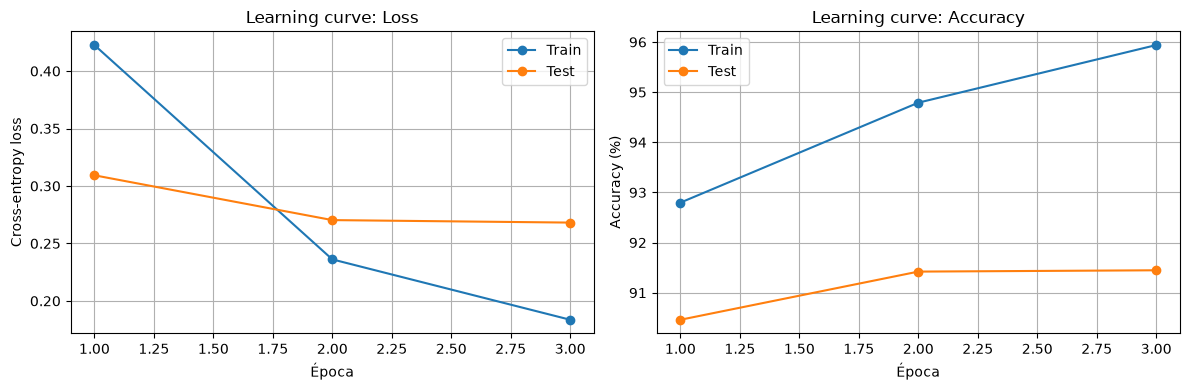

In [23]:
import matplotlib.pyplot as plt

epochs = range(1, NUM_EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Curva de pérdida
axes[0].plot(epochs, history["train_loss"], marker="o", label="Train")
axes[0].plot(epochs, history["test_loss"], marker="o", label="Test")
axes[0].set_title("Learning curve: Loss")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(True)

# Curva de accuracy
axes[1].plot(epochs, history["train_acc"], marker="o", label="Train")
axes[1].plot(epochs, history["test_acc"], marker="o", label="Test")
axes[1].set_title("Learning curve: Accuracy")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Modelo Inicial, 1 capa


Epoch 0/3: 100%|██████████| 1875/1875 [07:15<00:00,  4.30it/s, loss=0.205] 
Epoch [2/3]
Epoch 1/3: 100%|██████████| 1875/1875 [07:21<00:00,  4.25it/s, loss=0.202] 
Epoch [3/3]
Epoch 2/3: 100%|██████████| 1875/1875 [07:26<00:00,  4.20it/s, loss=0.0731]

Train accuracy: 95.75%

Test  accuracy: 91.55%

In [24]:
# --------------------------
# 8) Modelo RNN basico
# --------------------------
class RNNClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes,
                 num_layers=1, bidirectional=False, dropout=0.0, pad_idx=None):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.rnn = nn.RNN(
            input_size=embed_dim, hidden_size=hidden_dim, num_layers=num_layers,
            batch_first=True, bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0.0
        )
        out_dim = hidden_dim * (2 if bidirectional else 1)
        self.fc = nn.Linear(out_dim, num_classes)
        nn.init.xavier_uniform_(self.embedding.weight)
        with torch.no_grad():
            if pad_idx is not None:
                self.embedding.weight[pad_idx].fill_(0)

    def forward(self, x, lengths):
        emb = self.embedding(x)
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, h_n = self.rnn(packed)
        if self.rnn.bidirectional:
            last_hidden = torch.cat((h_n[-2], h_n[-1]), dim=1)
        else:
            last_hidden = h_n[-1]
        return self.fc(last_hidden)

# Misma semilla e hiperparametros para una comparacion justa con LSTM y GRU
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
rnn_model = RNNClassifier(
    len(itos), EMBED_DIM, HIDDEN_DIM, NUM_CLASSES, NUM_LAYERS, BIDIR, DROPOUT, PAD_IDX
).to(device)
history_rnn = train_model(rnn_model, train_loader, test_loader)
rnn_train_loss, rnn_train_acc = evaluate(rnn_model, train_loader)
rnn_test_loss, rnn_test_acc = evaluate(rnn_model, test_loader)
print(f"RNN - train acc: {rnn_train_acc:.2f}% | test acc: {rnn_test_acc:.2f}%")

Epoch 1/3: 100%|██████████| 1875/1875 [02:24<00:00, 13.01it/s, loss=0.5373]


Train loss: 0.7266 | Test loss: 0.4834 | Train acc: 86.42% | Test acc: 83.84%


Epoch 2/3: 100%|██████████| 1875/1875 [02:37<00:00, 11.92it/s, loss=0.3176]


Train loss: 0.3815 | Test loss: 0.4159 | Train acc: 90.29% | Test acc: 87.37%


Epoch 3/3: 100%|██████████| 1875/1875 [02:28<00:00, 12.62it/s, loss=0.3733]


Train loss: 0.3037 | Test loss: 0.3492 | Train acc: 92.97% | Test acc: 89.26%
RNN - train acc: 92.97% | test acc: 89.26%


In [25]:
# --------------------------
# 9) Modelo GRU
# --------------------------
class GRUClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes,
                 num_layers=1, bidirectional=False, dropout=0.0, pad_idx=None):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.gru = nn.GRU(
            input_size=embed_dim, hidden_size=hidden_dim, num_layers=num_layers,
            batch_first=True, bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0.0
        )
        out_dim = hidden_dim * (2 if bidirectional else 1)
        self.fc = nn.Linear(out_dim, num_classes)
        nn.init.xavier_uniform_(self.embedding.weight)
        with torch.no_grad():
            if pad_idx is not None:
                self.embedding.weight[pad_idx].fill_(0)

    def forward(self, x, lengths):
        emb = self.embedding(x)
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, h_n = self.gru(packed)
        if self.gru.bidirectional:
            last_hidden = torch.cat((h_n[-2], h_n[-1]), dim=1)
        else:
            last_hidden = h_n[-1]
        return self.fc(last_hidden)

torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
gru_model = GRUClassifier(
    len(itos), EMBED_DIM, HIDDEN_DIM, NUM_CLASSES, NUM_LAYERS, BIDIR, DROPOUT, PAD_IDX
).to(device)
history_gru = train_model(gru_model, train_loader, test_loader)
gru_train_loss, gru_train_acc = evaluate(gru_model, train_loader)
gru_test_loss, gru_test_acc = evaluate(gru_model, test_loader)
print(f"GRU - train acc: {gru_train_acc:.2f}% | test acc: {gru_test_acc:.2f}%")

# Resumen de los tres modelos (ejecutar despues de entrenar las tres celdas)
print("\nAccuracy de test:")
print(f"LSTM: {history['test_acc'][-1]:.2f}%")
print(f"RNN : {rnn_test_acc:.2f}%")
print(f"GRU : {gru_test_acc:.2f}%")

Epoch 1/3: 100%|██████████| 1875/1875 [05:16<00:00,  5.92it/s, loss=0.1817]


Train loss: 0.3552 | Test loss: 0.2516 | Train acc: 94.37% | Test acc: 91.84%


Epoch 2/3: 100%|██████████| 1875/1875 [05:24<00:00,  5.79it/s, loss=0.1152]


Train loss: 0.1953 | Test loss: 0.2601 | Train acc: 95.44% | Test acc: 91.45%


Epoch 3/3: 100%|██████████| 1875/1875 [05:21<00:00,  5.83it/s, loss=0.1327]


Train loss: 0.1504 | Test loss: 0.2554 | Train acc: 96.75% | Test acc: 91.92%
GRU - train acc: 96.75% | test acc: 91.92%

Accuracy de test:
LSTM: 91.45%
RNN : 89.26%
GRU : 91.92%
